
# Multiple Linear Regression




In [7]:
# Libraries
import numpy as np

# input

In [8]:
# 2 features
X = np.array([[1, 2],
              [2, 3],
              [4, 5],
              [6, 7]])

y = np.array([5, 8, 14, 20])

In [9]:
X.T

array([[1, 2, 4, 6],
       [2, 3, 5, 7]])

# weight w_1, w_2 and bais b

In [10]:
num_features = X.shape[1] # shape -> row, columns here we are getting columns
# W = np.zeros(num_features) # [0, 0] because for two features w_1 and w_2
W = np.array([0.5, 0.5])

b = 0.5 # bais


##  Predict in Multiple Linear Regression

###  We use the dot product here:
```python
np.dot(X, W)
```
## Example
```python
X = [[1, 2],
     [2, 3],
     [4, 5]]
W = [0.5, 0.7]
```

```python
[1*0.5 + 2*0.7,    # → 0.5 + 1.4 = 1.9
 2*0.5 + 3*0.7,    # → 1.0 + 2.1 = 3.1
 4*0.5 + 5*0.7]    # → 2.0 + 3.5 = 5.5
 ```

In [11]:
print(X)
print(W)
print(X.shape)
print(W.shape)
def predict(X, y, W, b):
  return np.dot(X, W) + b

[[1 2]
 [2 3]
 [4 5]
 [6 7]]
[0.5 0.5]
(4, 2)
(2,)


In [12]:
y_pred = predict(X, y, W, b)
print(y_pred)

[2. 3. 5. 7.]



## 📌 Compute Gradients for Linear Regression

---

### 🎯 Loss Function (MSE)

$$[
L = \frac{1}{n} \sum_{i=1}^{n} (y_i - (w_1 x_i + b))^2
]$$

Let:
$$[
u_i = y_i - (w_1 x_i + b)
\quad \Rightarrow \quad L = \frac{1}{n} \sum u_i^2
]$$

---

## 🔹 Derivative w.r.t \( b \) (Bias)

### 🧠 **Quick Matrix Style** (for notes/code):
$$[
\frac{\partial L}{\partial b} = -\frac{2}{n} \sum_{i=1}^{n} (y_i - (w_1 x_i + b))
]$$

### 📘 **Detailed Chain Rule**:
1. $$( u_i = y_i - (w_1 x_i + b) )$$
2. $$( L = u_i^2 )$$
3. Apply chain rule:

$$[
\frac{\partial L}{\partial b} = \frac{\partial L}{\partial u_i} \cdot \frac{\partial u_i}{\partial b}
= 2u_i \cdot (-1)
]$$

$$[
\Rightarrow \frac{\partial L}{\partial b} = -\frac{2}{n} \sum u_i = -\frac{2}{n} \sum (y_i - (w_1 x_i + b))
]$$

---

## 🔹 Derivative w.r.t \( w_1 \) (Weight)

### 🧠 **Quick Matrix Style** (for notes/code):
$$[
\frac{\partial L}{\partial w_1} = -\frac{2}{n} \sum_{i=1}^{n} x_i (y_i - (w_1 x_i + b))
]$$

### 📘 **Detailed Chain Rule**:
1. $$( u_i = y_i - (w_1 x_i + b))$$
2. $$( L = u_i^2)$$
3. Apply chain rule:

$$[
\frac{\partial L}{\partial w_1} = \frac{\partial L}{\partial u_i} \cdot \frac{\partial u_i}{\partial w_1}
= 2u_i \cdot (-x_i)
]$$

$$[
\Rightarrow \frac{\partial L}{\partial w_1} = -\frac{2}{n} \sum x_i (y_i - (w_1 x_i + b))
]$$

---

### ✅ Code Summary

```python
dw = (-2 / n) * np.dot(x.T * (y - y_pred)) # why dot cause in y_pred we did x * w using dot same here. y as single row but x has 2columns so transposed and used dot
db = (-2 / n) * np.sum(y - y_pred)


In [15]:
# Gradient descent
def compute_grad(X, y, W, b):

  #predict
  y_pred = predict(X, y, W, b)

  n = X.shape[0]

  #derivatie of MSE WRT weight(W)
  dW = (-2/n) * np.dot(X.T, (y -  y_pred))
  # print("dW : ", dW)

  #derivatie of MSE WRT bais(b)
  db = (-2/n) * np.sum(y -  y_pred)
  # print("db: ", db)

  # learning rate
  alpha = 0.001

  #update parameters
  W = W - (alpha * dW)
  b = b - (alpha * db)

  return W, b

In [16]:
for epochs in range(0, 100):
  if(epochs % 10 == 0):
      print("Epochs", epochs)
      print("Weight : ", W)
      print("bais : ", b)
      print("predict: ", predict(X, y, W, b))
  W, b = compute_grad(X, y, W, b)

Epochs 0
Weight :  [1.37157423 1.56547422]
bais :  0.6938999929466182
predict:  [ 5.19642267  8.13347113 14.00756804 19.88166495]
Epochs 10
Weight :  [1.37256926 1.56535657]
bais :  0.692787314998804
predict:  [ 5.19606971  8.13399554 14.00984719 19.88569884]
Epochs 20
Weight :  [1.37343942 1.5650924 ]
bais :  0.6916529768257075
predict:  [ 5.19527719  8.13380901 14.01087265 19.88793628]
Epochs 30
Weight :  [1.37424889 1.56476112]
bais :  0.6905122309190391
predict:  [ 5.19428335  8.13329336 14.01131337 19.88933338]
Epochs 40
Weight :  [1.37502761 1.56439978]
bais :  0.6893721717174425
predict:  [ 5.19319933  8.13262672 14.01148148 19.89033625]
Epochs 50
Weight :  [1.37578957 1.56402565]
bais :  0.6882360873180664
predict:  [ 5.19207696  8.13189219 14.01152263 19.89115308]
Epochs 60
Weight :  [1.37654131 1.5636468 ]
bais :  0.6871054899457845
predict:  [ 5.19094041  8.13112853 14.01150476 19.89188099]
Epochs 70
Weight :  [1.37728591 1.56326697]
bais :  0.6859810633513238
predict:  [ 5.

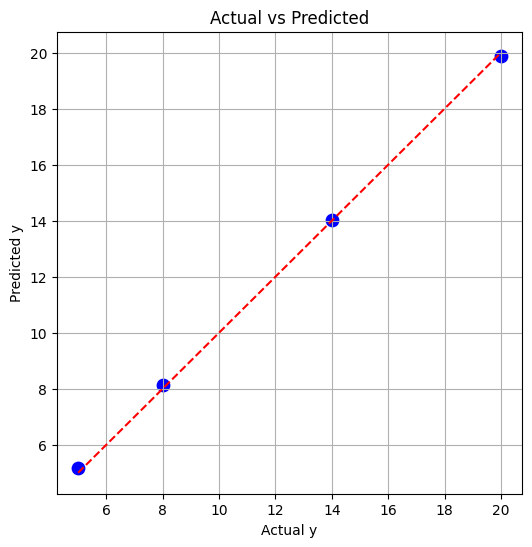

In [17]:
import matplotlib.pyplot as plt

y_pred = predict(X,y, W, b)

plt.figure(figsize=(6,6))
plt.scatter(y, y_pred, color='blue', s=80)

# Perfect prediction line
plt.plot([min(y), max(y)],
         [min(y), max(y)],
         color='red',
         linestyle='--')

plt.xlabel("Actual y")
plt.ylabel("Predicted y")
plt.title("Actual vs Predicted")
plt.grid(True)
plt.show()